# Classificação de dígitos manuscritos com KNN e validação cruzada

- **Repositório:** `machine-learning-portfolio`  
- **Tecnologias:** Scikit-Learn  
- **Arquivo Original:** `N_Fold_CrossValidation_protocol_KNN_digits_dataset (1).ipynb`  

---


In [1]:
# Importing the necessary classes/methods
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_digits
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score, f1_score


In [5]:
import pandas as pd
import numpy as np


# loading attribute names
att=pd.read_csv('glass.csv', index_col=-1, nrows=0).columns.tolist()
print(att)


# loading the data
dataset = np.loadtxt('glass.csv', delimiter=",", skiprows=1)
X = dataset[:,0:9]
y = dataset[:,9]
print(X.shape)


['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']
(214, 9)


Taxa de acerto (acurácia), média: 64.0531561461794
Taxa de acerto (acurácia), std: 5.022658123312761
Precision score: 0.6502411589392504
Recall score: 0.6401869158878505
F1 score: 0.641159216965953


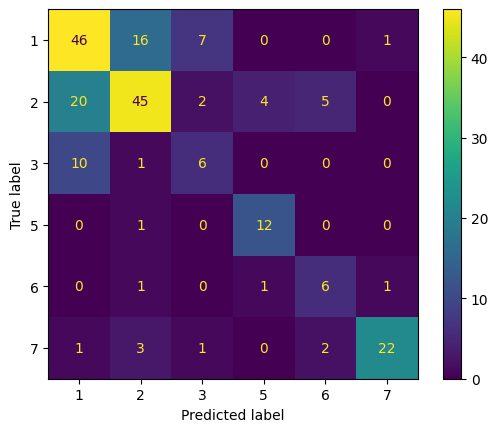

In [15]:
# Model declaration
knn = KNeighborsClassifier(
    n_neighbors=1,
    weights='uniform',
    algorithm='auto',
    leaf_size=30,
    metric='minkowski',
    p=2,
    metric_params=None,
    n_jobs=None
)

# Model training and evaluation
N_folds=5
result=cross_val_score(knn, X,y, cv=N_folds)
print('Taxa de acerto (acurácia), média:', result.mean() * 100)
print('Taxa de acerto (acurácia), std:', result.std() * 100)

# Test prediction
ypred=cross_val_predict(knn, X,y, cv=N_folds)

# Ploting the confusion matrix
cm=confusion_matrix(y, ypred)
disp=ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[1,2,3,5,6,7])
disp.plot()

# Precision
print('Precision score:', precision_score(y, ypred, average='weighted'))
# Recall
print('Recall score:', recall_score(y, ypred, average='weighted'))
# F1 score
print('F1 score:', f1_score(y, ypred, average='weighted'))


Taxa de acerto (acurácia), média: 97.67441860465115
Taxa de acerto (acurácia), std: 4.651162790697675
Precision score: 0.981386292834891
Recall score: 0.9766355140186916
F1 score: 0.9768685291079932


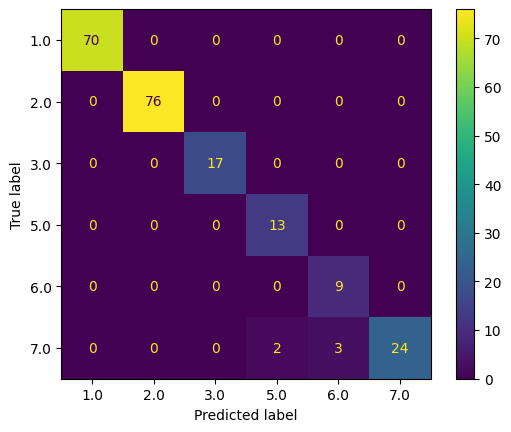

In [16]:
import pandas as pd
import numpy as np
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score

# Carregando os dados
dataset = np.loadtxt('glass.csv', delimiter=",", skiprows=1)

# Separando os atributos de entrada e as classes
X = dataset[:, 1:10]  # Ignorando o primeiro atributo (ID)
y = dataset[:, 9]    # A classe está na coluna 9

# Model declaration
nb = GaussianNB()

# Model training and evaluation
N_folds = 5
result = cross_val_score(nb, X, y, cv=N_folds)
print('Taxa de acerto (acurácia), média:', result.mean() * 100)
print('Taxa de acerto (acurácia), std:', result.std() * 100)

# Test prediction
ypred = cross_val_predict(nb, X, y, cv=N_folds)

# Ploting the confusion matrix
cm = confusion_matrix(y, ypred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y))
disp.plot()

# Precision
print('Precision score:', precision_score(y, ypred, average='weighted'))
# Recall
print('Recall score:', recall_score(y, ypred, average='weighted'))
# F1 score
print('F1 score:', f1_score(y, ypred, average='weighted'))


Taxa de acerto (acurácia), média: 99.53488372093024
Taxa de acerto (acurácia), std: 0.9302325581395366
Precision score: 1.0
Recall score: 1.0
F1 score: 1.0


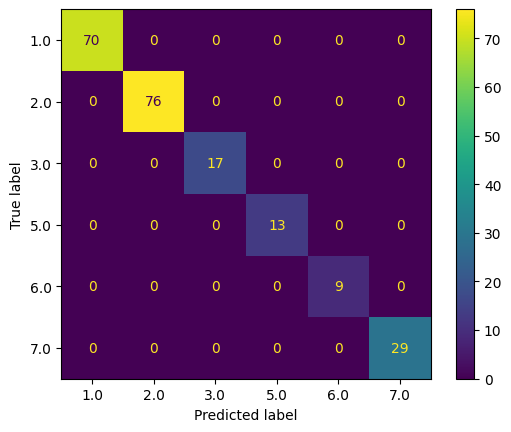

In [19]:
import pandas as pd
import numpy as np
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score

# Carregando os dados
dataset = np.loadtxt('glass.csv', delimiter=",", skiprows=1)

# Separando os atributos de entrada e as classes
X = dataset[:, 1:10]  # Ignorando o primeiro atributo (ID)
y = dataset[:, 9]    # A classe está na coluna 9

# Model declaration with parameters
dtree = DecisionTreeClassifier(
    criterion='gini',
    splitter='best',
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=None,
    random_state=None
)

# Model training and evaluation
N_folds = 5
result = cross_val_score(dtree, X, y, cv=N_folds)
print('Taxa de acerto (acurácia), média:', result.mean() * 100)
print('Taxa de acerto (acurácia), std:', result.std() * 100)

# Test prediction
ypred = cross_val_predict(dtree, X, y, cv=N_folds)

# Ploting the confusion matrix
cm = confusion_matrix(y, ypred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y))
disp.plot()

# Precision
print('Precision score:', precision_score(y, ypred, average='weighted'))
# Recall
print('Recall score:', recall_score(y, ypred, average='weighted'))
# F1 score
print('F1 score:', f1_score(y, ypred, average='weighted'))


Taxa de acerto (acurácia), média: 35.51495016611296
Taxa de acerto (acurácia), std: 0.9061914748827806
Precision score: 0.12612455236265177
Recall score: 0.35514018691588783
F1 score: 0.18614244279729297


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


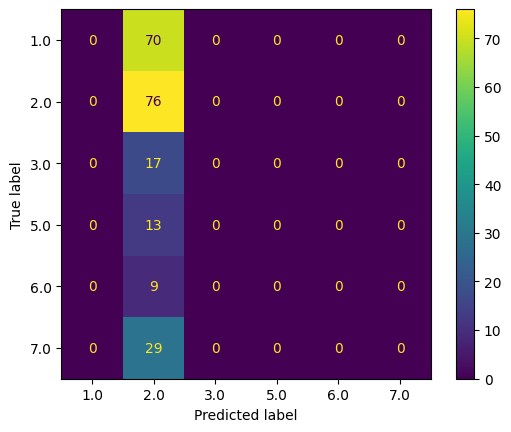

In [21]:
import pandas as pd
import numpy as np
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.svm import SVC
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score

# Carregando os dados
dataset = np.loadtxt('glass.csv', delimiter=",", skiprows=1)

# Separando os atributos de entrada e as classes
X = dataset[:, 1:10]  # Ignorando o primeiro atributo (ID)
y = dataset[:, 9]    # A classe está na coluna 9

# Model declaration with parameters
svm_classifier = SVC(
    C=1.0,                  # Penalidade de erro
    kernel='rbf',          # Tipo de kernel (rbf, linear, polynomial, sigmoid)
    degree=3,              # Grau do polinômio (se kernel for 'poly')
    gamma='scale',         # Coeficiente do kernel (auto, scale, ou um valor float)
    coef0=0.0,             # Termo independente no kernel (se kernel for 'poly' ou 'sigmoid')
    shrinking=True,        # Habilita a heurística de redução de solução
    probability=False,     # Habilita a estimativa de probab
